# **Prediksi Popularitas Artikel Berita Online Menggunakan Model Regresi Berbasis Gradient Boosting**

#**Library**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

#**Mount Google Drive**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path = "/content/drive/MyDrive/AI_Project/OnlineNewsPopularity.csv"
df = pd.read_csv(path)
df.head()

,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


##**Load Dataset**

In [ ]:
print("Shape:", df.shape)
df.describe()

Shape: (39644, 61)


,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,...,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,354.530471,10.398749,546.514731,0.548216,0.996469,0.689175,10.883690,3.293638,4.544143,1.249874,...,0.095446,0.756728,-0.259524,-0.521944,-0.107500,0.282353,0.071425,0.341843,0.156064,3395.380184
std,214.163767,2.114037,471.107508,3.520708,5.231231,3.264816,11.332017,3.855141,8.309434,4.107855,...,0.071315,0.247786,0.127726,0.290290,0.095373,0.324247,0.265450,0.188791,0.226294,11626.950749
min,8.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,1.000000
25%,164.000000,9.000000,246.000000,0.470870,1.000000,0.625739,4.000000,1.000000,1.000000,0.000000,...,0.050000,0.600000,-0.328383,-0.700000,-0.125000,0.000000,0.000000,0.166667,0.000000,946.000000
50%,339.000000,10.000000,409.000000,0.539226,1.000000,0.690476,8.000000,3.000000,1.000000,0.000000,...,0.100000,0.800000,-0.253333,-0.500000,-0.100000,0.150000,0.000000,0.500000,0.000000,1400.000000
75%,542.000000,12.000000,716.000000,0.608696,1.000000,0.754630,14.000000,4.000000,4.000000,1.000000,...,0.100000,1.000000,-0.186905,-0.300000,-0.050000,0.500000,0.150000,0.500000,0.250000,2800.000000
max,731.000000,23.000000,8474.000000,701.000000,1042.000000,650.000000,304.000000,116.000000,128.000000,91.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,1.000000,843300.000000


#**Preprocessing**

###**Cek Duplikasi & Hapus**

In [ ]:
duplicate_count = df.duplicated().sum()
print("Jumlah duplikasi:", duplicate_count)

df = df.drop_duplicates()
print("Baris setelah hapus duplikat:", df.shape[0])

Jumlah duplikasi: 0
Baris setelah hapus duplikat: 39644


###**Missing Value**

In [ ]:
df.isnull().sum()

,0
url,0
timedelta,0
n_tokens_title,0
n_tokens_content,0
n_unique_tokens,0
...,...
title_subjectivity,0
title_sentiment_polarity,0
abs_title_subjectivity,0
abs_title_sentiment_polarity,0


###**Handling Outliers – Log Transform Target (shares)**

In [ ]:
df.columns = df.columns.str.strip()
df['shares_log'] = np.log1p(df['shares'])
print(df['shares'].describe())

count     39644.000000
mean       3395.380184
std       11626.950749
min           1.000000
25%         946.000000
50%        1400.000000
75%        2800.000000
max      843300.000000
Name: shares, dtype: float64


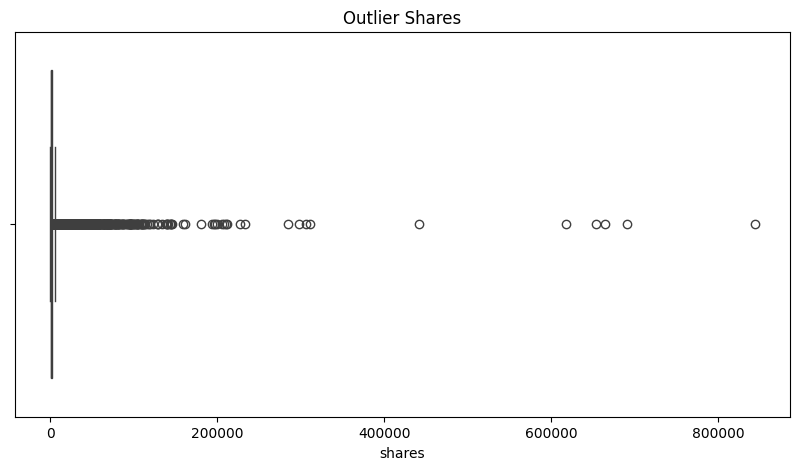

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df['shares'])
plt.title("Outlier Shares")
plt.show()

###**Hapus Kolom Tidak Dibutuhkan**

In [ ]:
df = df.drop(['url', 'timedelta'], axis=1, errors='ignore')

In [ ]:
df.columns

Index(['n_tokens_title', 'n_tokens_content', 'n_unique_tokens',
       'n_non_stop_words', 'n_non_stop_unique_tokens', 'num_hrefs',
       'num_self_hrefs', 'num_imgs', 'num_videos', 'average_token_length',
       'num_keywords', 'data_channel_is_lifestyle',
       'data_channel_is_entertainment', 'data_channel_is_bus',
       'data_channel_is_socmed', 'data_channel_is_tech',
       'data_channel_is_world', 'kw_min_min', 'kw_max_min', 'kw_avg_min',
       'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg',
       'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares',
       'self_reference_avg_sharess', 'weekday_is_monday', 'weekday_is_tuesday',
       'weekday_is_wednesday', 'weekday_is_thursday', 'weekday_is_friday',
       'weekday_is_saturday', 'weekday_is_sunday', 'is_weekend', 'LDA_00',
       'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity',
       'global_sentiment_polarity', 'global_rate_positive_words',
       'global_rate_negat

In [ ]:
df.head()

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares,shares_log
0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,4.680365,...,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593,6.386879
1,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,4.913725,...,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711,6.568078
2,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,4.393365,...,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500,7.313887
3,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,4.404896,...,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200,7.090910
4,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,0.0,4.682836,...,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505,6.226537


In [ ]:
print("Sebelum:", df.shape)
df = df.drop(['url', 'timedelta'], axis=1, errors='ignore')
print("Sesudah:", df.shape)

Sebelum: (39644, 60)
Sesudah: (39644, 60)


###**Feature Selection Pisahkan Fitur dan Target**

In [ ]:
X = df.drop(['shares', 'shares_log'], axis=1)
y = df['shares_log']

#**Feature Engineering**

###**Rasio Kata Unik**

In [ ]:
df['unique_word_ratio'] = df['n_unique_tokens'] / (df['n_tokens_content'] + 1)

###**Kompleksitas Konten Panjang Artikel Jumlah Gambar**

In [ ]:
df['unique_word_ratio'] = df['n_unique_tokens'] / (df['n_tokens_content'] + 1)
df[['n_unique_tokens', 'n_tokens_content', 'unique_word_ratio']].head()

,n_unique_tokens,n_tokens_content,unique_word_ratio
0,0.663594,219.0,0.003016
1,0.604743,255.0,0.002362
2,0.575130,211.0,0.002713
3,0.503788,531.0,0.000947
4,0.415646,1072.0,0.000387


###**Kombinasi Keyword**

In [ ]:
df['kw_combined'] = df['kw_avg_avg'] * df['kw_max_avg']
df[['kw_avg_avg', 'kw_max_avg', 'kw_combined']].head()

,kw_avg_avg,kw_max_avg,kw_combined
0,0.0,0.0,0.0
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0


###**Jumlah Weekday yang Aktif**

In [ ]:
weekday_cols = [
    'weekday_is_monday','weekday_is_tuesday','weekday_is_wednesday',
    'weekday_is_thursday','weekday_is_friday'
]
df['weekday_total'] = df[weekday_cols].sum(axis=1)
df[['weekday_is_monday','weekday_is_friday','weekday_total']].head()

,weekday_is_monday,weekday_is_friday,weekday_total
0,1.0,0.0,1.0
1,1.0,0.0,1.0
2,1.0,0.0,1.0
3,1.0,0.0,1.0
4,1.0,0.0,1.0


#**Train-Test Split**

In [ ]:
X = df.drop(['shares', 'shares_log'], axis=1)
y = df['shares_log']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
X_train.shape, X_test.shape
y_train.shape, y_test.shape

((31715,), (7929,))

#**Feature Scaling (Setelah Split)**

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled.mean()
X_train_scaled.std()

np.float64(0.9999999999999999)

#**Exploratory Data Analysis (EDA)**

##**Statistik Deskriptif**

In [ ]:
df.describe()

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares,shares_log,unique_word_ratio,kw_combined,weekday_total
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,...,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,3.964400e+04,39644.000000
mean,10.398749,546.514731,0.548216,0.996469,0.689175,10.883690,3.293638,4.544143,1.249874,4.548239,...,-0.107500,0.282353,0.071425,0.341843,0.156064,3395.380184,7.475692,0.001791,2.426681e+07,0.869085
std,2.114037,471.107508,3.520708,5.231231,3.264816,11.332017,3.855141,8.309434,4.107855,0.844406,...,0.095373,0.324247,0.265450,0.188791,0.226294,11626.950749,0.929674,0.002964,1.321008e+08,0.337312
min,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,-1.000000,0.000000,-1.000000,0.000000,0.000000,1.000000,0.693147,0.000000,0.000000e+00,0.000000
25%,9.000000,246.000000,0.470870,1.000000,0.625739,4.000000,1.000000,1.000000,0.000000,4.478404,...,-0.125000,0.000000,0.000000,0.166667,0.000000,946.000000,6.853299,0.000614,8.659563e+06,1.000000
50%,10.000000,409.000000,0.539226,1.000000,0.690476,8.000000,3.000000,1.000000,0.000000,4.664082,...,-0.100000,0.150000,0.000000,0.500000,0.000000,1400.000000,7.244942,0.001238,1.235586e+07,1.000000
75%,12.000000,716.000000,0.608696,1.000000,0.754630,14.000000,4.000000,4.000000,1.000000,4.854839,...,-0.050000,0.500000,0.150000,0.500000,0.250000,2800.000000,7.937732,0.002275,2.175565e+07,1.000000
max,23.000000,8474.000000,701.000000,1042.000000,650.000000,304.000000,116.000000,128.000000,91.000000,8.041534,...,0.000000,1.000000,1.000000,0.500000,1.000000,843300.000000,13.645079,0.446213,1.300059e+10,1.000000


##**Distribusi Target Sebelum & Sesudah Log Transform**

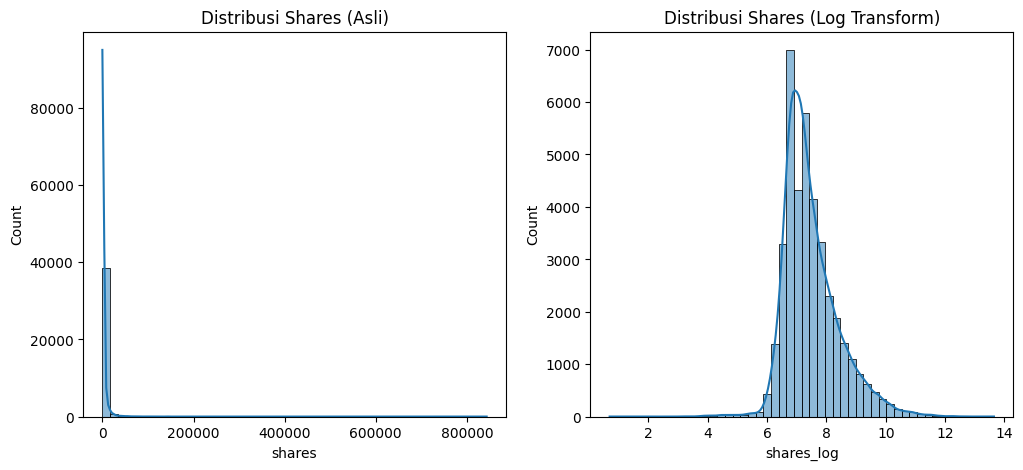

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12,5))

sns.histplot(df['shares'], bins=50, ax=ax[0], kde=True)
ax[0].set_title("Distribusi Shares (Asli)")

sns.histplot(df['shares_log'], bins=50, ax=ax[1], kde=True)
ax[1].set_title("Distribusi Shares (Log Transform)")

plt.show()

##**Korelasi Variabel**

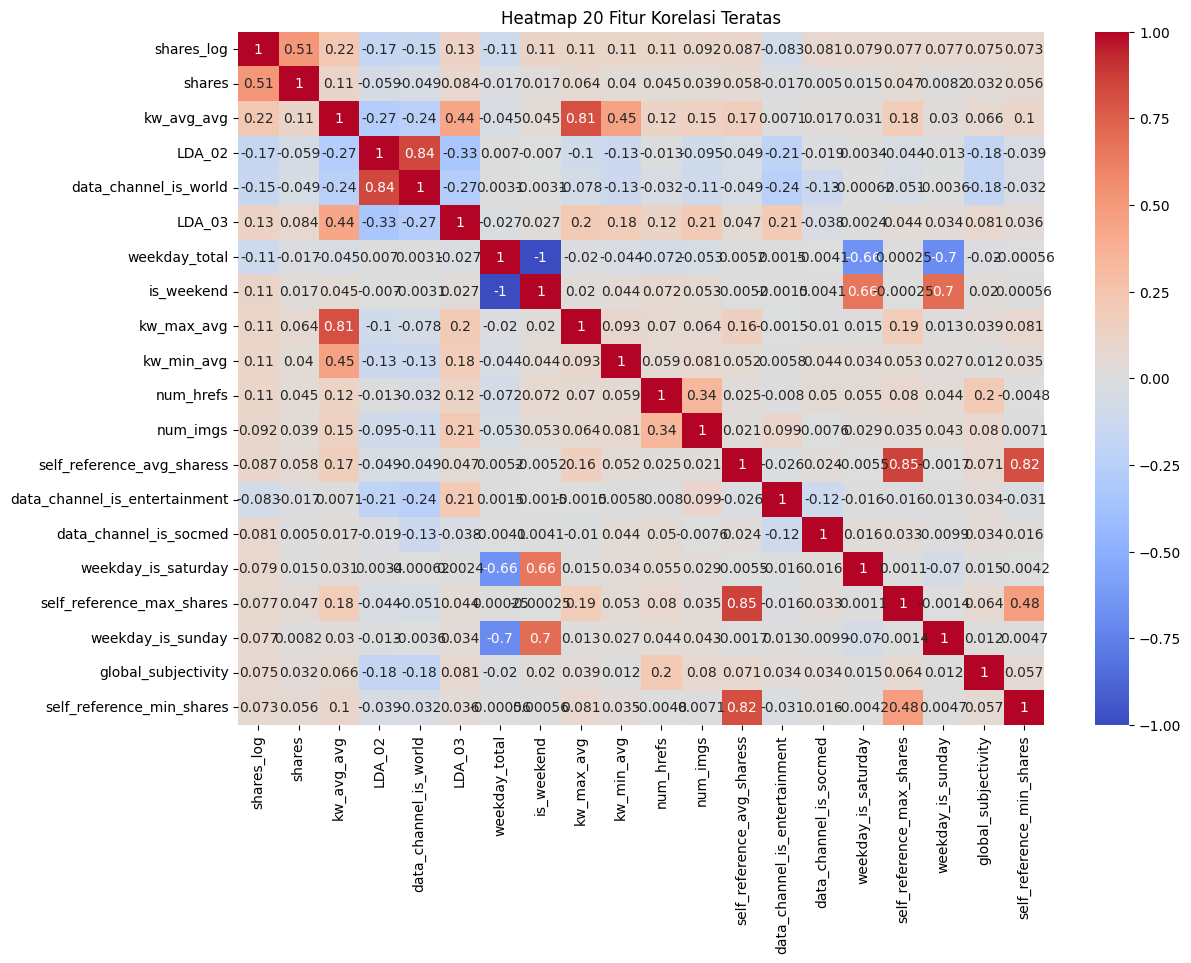

In [ ]:
plt.figure(figsize=(13,9))
top_corr = df.corr()['shares_log'].abs().sort_values(ascending=False).head(20).index
sns.heatmap(df[top_corr].corr(), annot=True, cmap='coolwarm')
plt.title("Heatmap 20 Fitur Korelasi Teratas")
plt.show()

#**Modeling**

##**Baseline Model Linear Regression**

In [ ]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
pred_lr = lr.predict(X_test_scaled)

print("Baseline Linear Regression")
print("MAE:", mean_absolute_error(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R²:", r2_score(y_test, pred_lr))

Baseline Linear Regression
MAE: 0.6435373858317878
RMSE: 0.8644527320394101
R²: 0.12823904763480198


##**Gradient Boosting Regressor**

In [ ]:
gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train_scaled, y_train)
pred_gbr = gbr.predict(X_test_scaled)

print("Gradient Boosting")
print("MAE:", mean_absolute_error(y_test, pred_gbr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_gbr)))
print("R²:", r2_score(y_test, pred_gbr))

Gradient Boosting
MAE: 0.6274666412563015
RMSE: 0.844329296722284
R²: 0.16835376161022442


##**Hyperparameter Tuning (GridSearchCV)**

In [ ]:
param_grid = {
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200],
    'max_depth': [3, 5]
}
grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)
print("Best Params:", grid.best_params_)

Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}


In [ ]:
print("Best Params:", grid.best_params_)
print("Best CV R2:", grid.best_score_)

Best Params: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Best CV R2: 0.16140733748510439


##**Train Model Final**

In [ ]:
best_model = grid.best_estimator_
pred_final = best_model.predict(X_test_scaled)

print("Gradient Boosting (Best Model)")
print("MAE:", mean_absolute_error(y_test, pred_final))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_final)))
print("R²:", r2_score(y_test, pred_final))

Gradient Boosting (Best Model)
MAE: 0.62469154320457
RMSE: 0.8412150063849835
R²: 0.1744774654713862


#**Evaluasi**

In [ ]:
print("PERBANDINGAN MODEL")
print("Linear Regression R² :", r2_score(y_test, pred_lr))
print("Gradient Boosting R²   :", r2_score(y_test, pred_gbr))
print("Gradient Boosting Tuning R²   :", r2_score(y_test, pred_final))

PERBANDINGAN MODEL
Linear Regression R² : 0.12823904763480198
Gradient Boosting R²   : 0.16835376161022442
Gradient Boosting Tuning R²   : 0.1744774654713862


##**Feature Importance**

In [ ]:
importances = best_model.feature_importances_
feat_names = X.columns

feat_imp = pd.DataFrame({
    'Feature': feat_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

feat_imp.head(10)

,Feature,Importance
25,kw_avg_avg,0.180239
28,self_reference_avg_sharess,0.065842
26,self_reference_min_shares,0.057932
59,kw_combined,0.042547
5,num_hrefs,0.033019
24,kw_max_avg,0.029184
23,kw_min_avg,0.025397
39,LDA_02,0.024980
42,global_subjectivity,0.023511
37,LDA_00,0.022469


##**Visualisasi Feature Importance**

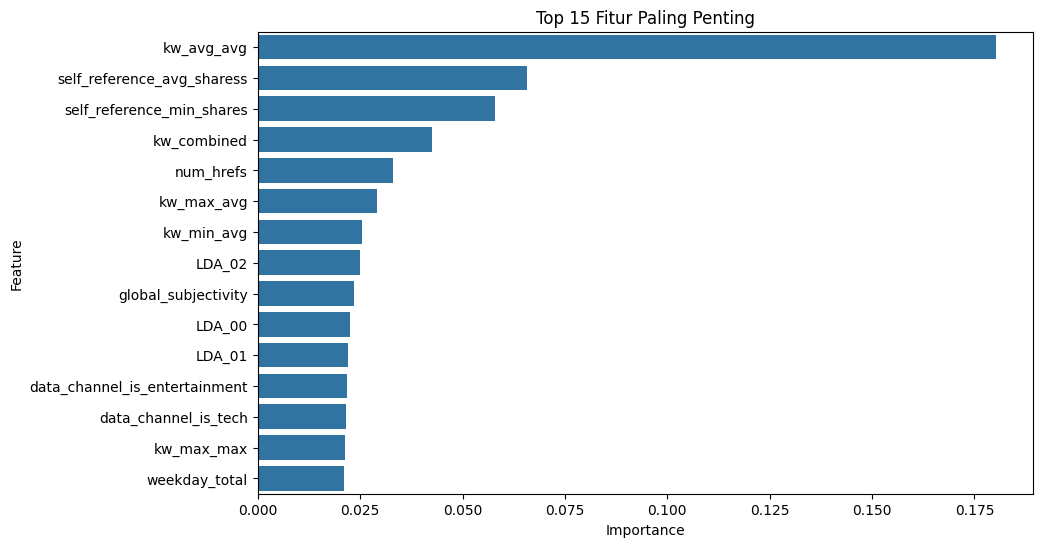

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x=feat_imp['Importance'].head(15),
            y=feat_imp['Feature'].head(15))
plt.title("Top 15 Fitur Paling Penting")
plt.show()

#**Analisis Hasil**

In [ ]:
print("Analisis Model")
print("Model terbaik:", best_model)
print("Fitur paling berpengaruh:\n", feat_imp.head(10))

Analisis Model
Model terbaik: GradientBoostingRegressor(learning_rate=0.05, max_depth=5, n_estimators=200,
                          random_state=42)
Fitur paling berpengaruh:
                        Feature  Importance
25                  kw_avg_avg    0.180239
28  self_reference_avg_sharess    0.065842
26   self_reference_min_shares    0.057932
59                 kw_combined    0.042547
5                    num_hrefs    0.033019
24                  kw_max_avg    0.029184
23                  kw_min_avg    0.025397
39                      LDA_02    0.024980
42         global_subjectivity    0.023511
37                      LDA_00    0.022469


/tmp/ipython-input-952845683.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_10, palette='viridis')


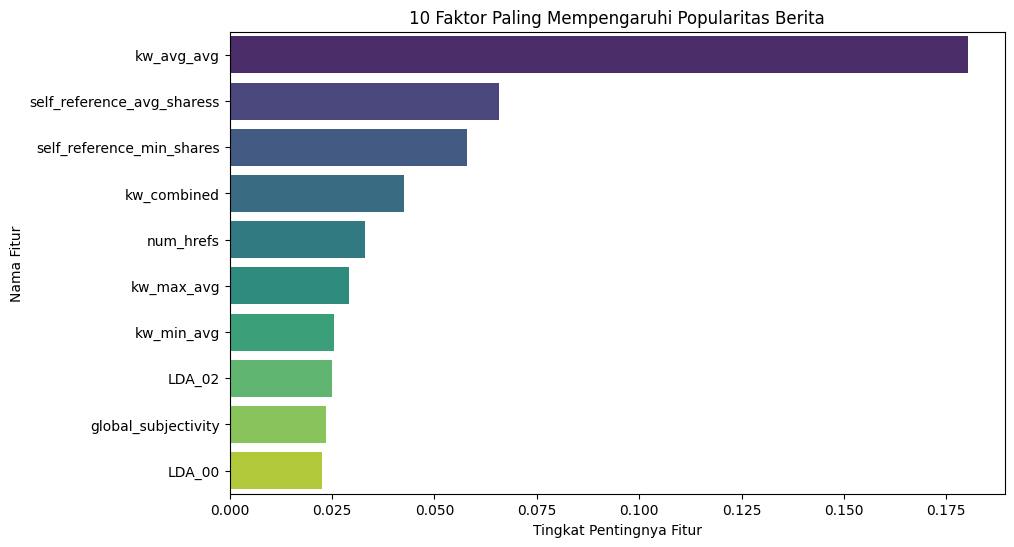

In [ ]:
top_10 = feat_imp.head(10)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_10, palette='viridis')
plt.title('10 Faktor Paling Mempengaruhi Popularitas Berita')
plt.xlabel('Tingkat Pentingnya Fitur')
plt.ylabel('Nama Fitur')
plt.show()